In [32]:
import pya
from pya import *
import SiEPIC
from SiEPIC._globals import Python_Env
from SiEPIC.scripts import connect_cell, connect_pins_with_waveguide, zoom_out, export_layout
from SiEPIC.utils import create_cell2, get_layout_variables
from SiEPIC.utils.layout import new_layout, floorplan, coupler_array
from SiEPIC.extend import to_itype
from SiEPIC.verification import layout_check
import numpy as np
from SiEPIC.scripts import connect_pins_with_waveguide, connect_cell
import os
import sys
from SiEPIC.utils import klive

# Generic Imports
import os
import pya
from pya import *
import numpy as np
import pandas as pd
from SiEPIC.utils import klive
from SiEPIC.scripts import connect_pins_with_waveguide, zoom_out, export_layout
from SiEPIC._globals import Python_Env
from SiEPIC.utils.layout import new_layout
import sys
import openpyxl


if Python_Env == 'Script':

    # Define the path to your local PDK
    path_to_pdk = r"D:\GitHub"
    # path_GitHub = r"C:\Users\gamem\OneDrive - UBC\Documents\GitHub"

    sys.path.insert(0, os.path.join(path_to_pdk, "Shallow_Etch_BTO_PDK","klayout"))

    # Now try importing the PDK
    import Shallow_Etch_BTO



In [33]:
tech_name = 'Shallow_Etch_BTO'  
gclib_name = 'Shallow_Etch_BTO'
lib_name = 'Shallow_Etch_BTO'


chip_name = 'SiEPICfab_bto'  # Change this to the name of the .oas file from the folder gds_floorplan
chip_folder = 'SiEPICfab_bto'


chip_file = os.path.join("gds_floorplan", f"{chip_name}.oas")  # Main chip file in floorplan

def GDS_Export(topcell,cellname):
    # Export for fabrication, removing PCells
    path = os.path.join(f"gds_in")
    #r"D:\Github\SiEPIC-Klayout-in-VSCode\floorplan_btomrr\gds_in"

    file_out = export_layout(topcell, path, cellname, relative_path = '', format='gds', screenshot=True)

    # Display the layout in KLayout, using KLayout Package "klive", which needs to be installed in the KLayout Application
    if Python_Env == 'Script':
        klive.show(file_out, technology=tech_name)

    print('\n COMPLETED \n')


In [34]:
cell1_name = 'cell_ring'  # Change this to the name of the top cell from the floorplan

chip_file = os.path.join("gds_floorplan", f"{chip_name}.oas")  # Main chip file in floorplan
layout_file = os.path.join("designs", f"{cell1_name}.oas")  # Name of the soon-to-be chip


Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmpoiwp6odw\\cell_ring.gds"}
Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmpoiwp6odw\\cell_ring.gds"}


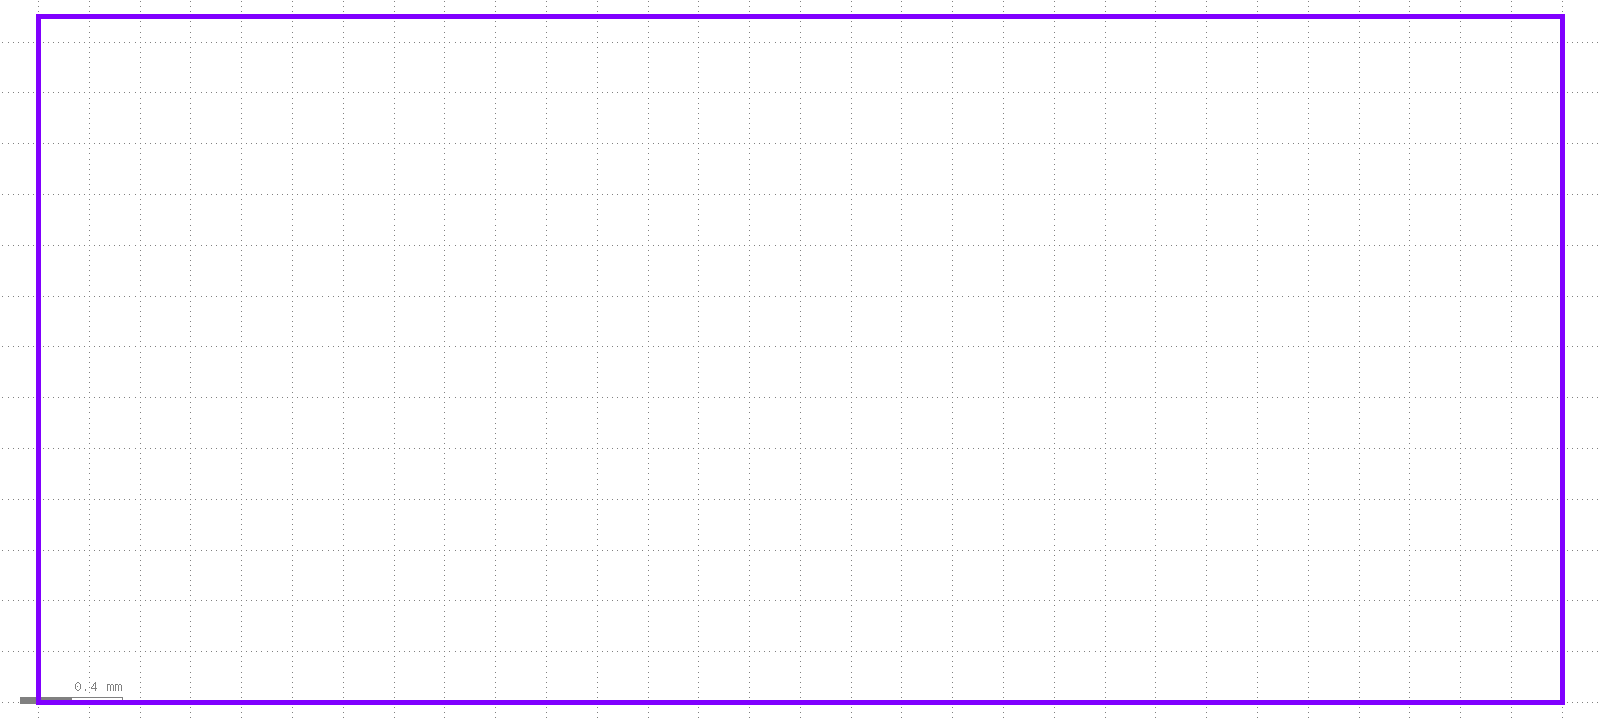

In [35]:
"""
This script is used to extract a cell from a floorplan and save it as a GDS file.
Worry less about it, just run it and it will do the job.
"""

_, _ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
_ly.read(chip_file)
_top_cell = _ly.cell(cell1_name)
_top_cell.write(layout_file) #save the layout to a GDS file

"""
This script is used to open a GDS file and display it in KLayout.
Creates a new layout and reads the GDS file the above cell made.
"""


_, ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
ly.read(layout_file)
# Access the top cell
top_cell = ly.cell(cell1_name)

dbu = ly.dbu
wg_bend_radius = 20
              

top_cell.plot() # in the browser
top_cell.show() # in KLayout

top_cell.bbox().width()*dbu, top_cell.bbox().height()*dbu, top_cell.bbox().right, top_cell.bbox().top # just useful to confirm the size of the cell
# Zoom out
# zoom_out(cell)
top_cell.show() # in KLayout GUI
top_cell.plot() # in the browser

In [36]:
# ============================================================
# GC settings profiles
# Define once and reuse in later cells
# ============================================================
GC_SETTING_FIXED = {
    "gc_cell_name": "BTO_ShEtch_GC_1550",
    "gc_library": gclib_name,
    "gc_pitch": 127.0,   # microns
    "default_num_gc": 4,
    "label_location": 1,
}

GC_SETTINGS_UNIVERSAL = {
    "gc_cell_name": "BTO_Universal_GC",
    "gc_library": gclib_name,
    "gc_pitch": 127.0,
    "default_num_gc": 2,
    "label_location": 1,
    "parameters": {
        "target_length": 25,
        "duty_cycle": 0.45,
        "pitch": 1.045,
        "radius": 25,
        "y_span": 15,
        "L_extra": 5,
        "wg_width": 1.0,
    }
}


WG_SETTINGS = {
    "wg_type": "Low-loss Bend Waveguide, w=1.0um r=50um",
}
device_prefix = "opt_in_TE_1550_device_XX"

# margin_x = 250

In [37]:
def place_gc_loopback(
    ParentCell=None,
    x_pos_GC=0,
    y_pos_GC=None,
    cellname="gc_loopback",
    device_label="opt_in_TE_1550_device_JSong_Loopback",
    xmax=None,
    num_gc=None,
    port_pairs=[(0, 1)],
    x_spacing=20.0,
    row_spacing=None,
    turtle_A=[75, 90, 127, -90, 75],
    gc_setting=None,
    tech_name_input=None,
    layout=None,
):
    """
    Place a GC array and connect selected GC pairs with loopback waveguides.

    Expected gc_setting input:
    - GC_SETTING_FIXED
    - GC_SETTINGS_UNIVERSAL
    or a copied/modified dict (e.g., pitch sweep based on GC_SETTINGS_UNIVERSAL).
    """

    parent_cell = top_cell if ParentCell is None else ParentCell
    if parent_cell is None:
        raise ValueError("ParentCell is required when top_cell is not available")

    ly_local = layout if layout is not None else parent_cell.layout()
    if ly_local is None:
        raise ValueError("Could not resolve layout. Pass layout=ly explicitly.")

    if gc_setting is None:
        gc_setting = GC_SETTING_FIXED

    if not isinstance(gc_setting, dict):
        raise TypeError("gc_setting must be a dict (e.g., GC_SETTING_FIXED or GC_SETTINGS_UNIVERSAL)")

    # Copy to protect global dictionaries when sweeping parameters.
    active_gc_settings = dict(gc_setting)
    active_gc_settings["parameters"] = dict(active_gc_settings.get("parameters", {}))

    # Use global WG_SETTINGS as requested.
    wg_type = WG_SETTINGS.get("wg_type", "")

    # tech_name from input first; fallback to gc settings then global.
    tech_local = tech_name_input if tech_name_input is not None else globals().get("tech_name", None)
    tech_local = active_gc_settings.get("tech_name", tech_local)

    gc_cell_name = active_gc_settings["gc_cell_name"]
    gc_library = active_gc_settings["gc_library"]
    gc_pitch = active_gc_settings["gc_pitch"]
    label_location = active_gc_settings["label_location"]
    gc_parameters = active_gc_settings.get("parameters", {})

    if num_gc is None:
        num_gc = active_gc_settings["default_num_gc"]

    if y_pos_GC is None:
        y_pos_GC = parent_cell.bbox().height() * dbu

    if xmax is None:
        xmax = parent_cell.bbox().width() * dbu

    if row_spacing is None:
        row_spacing = (num_gc - 1) * gc_pitch + 2 * wg_bend_radius

    gc_ports = ["opt1"] * num_gc

    if num_gc < 2:
        raise ValueError("num_gc must be at least 2")

    for pair in port_pairs:
        if len(pair) != 2:
            raise ValueError(f"Each entry in port_pairs must have 2 indices, got {pair}")
        i, j = pair
        if not (0 <= i < num_gc and 0 <= j < num_gc):
            raise ValueError(f"Invalid GC pair {pair} for num_gc={num_gc}")

    # Normalize turtle paths.
    # None or [] means auto-routing (no explicit turtle path).
    if turtle_A is None or turtle_A == []:
        turtle_list = [None for _ in port_pairs]
    elif len(port_pairs) == 1:
        turtle_list = [turtle_A]
    else:
        if isinstance(turtle_A, list) and len(turtle_A) > 0 and isinstance(turtle_A[0], list):
            if len(turtle_A) != len(port_pairs):
                raise ValueError("Number of turtle paths must match number of port pairs")
            turtle_list = turtle_A
        else:
            turtle_list = [turtle_A for _ in port_pairs]

    cell = ly_local.create_cell(cellname)

    use_universal_gc = gc_cell_name == "BTO_Universal_GC"

    # Universal/self-defined path: create parameterized PCell from tech.
    # Fixed path: use library loader and fall back to create_cell2 for robustness.
    if use_universal_gc:
        if tech_local is None:
            raise ValueError("tech_name_input is required for UNIVERSAL GC creation")
        gc_probe = ly_local.create_cell("BTO_Universal_GC", tech_local, gc_parameters)
    else:
        gc_probe = None
        if gc_parameters:
            gc_probe = ly_local.create_cell(gc_cell_name, gc_library, gc_parameters)
        if gc_probe is None:
            gc_probe = create_cell2(ly_local, gc_cell_name, gc_library)

    if gc_probe is None:
        raise ValueError(
            f"Could not create/load GC cell '{gc_cell_name}' from library/tech '{gc_library}' with parameters {gc_parameters}"
        )

    top_boundary = parent_cell.bbox().height() * dbu
    near_left = x_pos_GC < 100
    near_right = x_pos_GC > xmax - 150
    near_top = y_pos_GC > top_boundary - 100
    near_bottom = y_pos_GC == 0

    if y_pos_GC == top_boundary or near_top:
        y_pos_GC -= (num_gc - 1) * gc_pitch + gc_probe.bbox().height() * dbu / 2
        if x_pos_GC == 0 or near_left:
            x_pos_GC = gc_probe.bbox().width() * dbu
        elif near_right:
            x_pos_GC = xmax - gc_probe.bbox().width() * dbu
    elif near_bottom:
        y_pos_GC += gc_probe.bbox().height() * dbu / 2
        if near_left:
            x_pos_GC = gc_probe.bbox().width() * dbu
        elif near_right:
            x_pos_GC = xmax - gc_probe.bbox().width() * dbu

    # Keep GC anchor fixed inside each device cell; move each device cell in top cell instead.
    # Set local Y so bottom GC opt1 pin is exactly at y=0 in device-cell coordinates.
    local_gc_x = gc_probe.bbox().width() * dbu
    try:
        gc_pin_probe_y = gc_probe.find_pin("opt1").center.to_dtype(dbu).y
    except Exception:
        gc_pin_probe_y = 0.0
    local_gc_y = -gc_pin_probe_y
    cell_origin_x = x_pos_GC 
    cell_origin_y = y_pos_GC
    parent_cell.insert(
        CellInstArray(
            cell.cell_index(),
            Trans(Trans.R0, to_itype(cell_origin_x, dbu), to_itype(cell_origin_y, dbu)),
        )
    )

    # if use_universal_gc:
    #     inst_GCs = coupler_array(
    #         cell,
    #         cell_name=gc_cell_name,  # "BTO_Universal_GC",
    #         cell_library=gc_library,
    #         cell_params=gc_parameters,
    #         x_offset=local_gc_x / dbu,
    #         y_offset=local_gc_y / dbu,
    #         label=device_label,
    #         label_location=label_location,
    #         count=num_gc,
    #     )

    # else:
    #     inst_GCs = coupler_array(
    #         cell,
    #         cell_name=gc_cell_name,
    #         cell_library=gc_library,
    #         x_offset=local_gc_x / dbu,
    #         y_offset=local_gc_y / dbu,
    #         label=device_label,
    #         label_location=label_location,
    #         count=num_gc,
    #     )
    inst_GCs = []
    x_i = to_itype(local_gc_x, dbu)
    for i in range(num_gc):
        y_i = to_itype(local_gc_y + i * gc_pitch, dbu)
        inst = cell.insert(CellInstArray(gc_probe.cell_index(), Trans(Trans.R0, x_i, y_i)))
        inst_GCs.append(inst)
    label_x = to_itype(local_gc_x, dbu)
    label_y = to_itype(0 + label_location * gc_pitch, dbu)
    label = pya.Text(
        f"{device_label}",
        pya.Trans(pya.Trans.R0, label_x, label_y),
    )
    cell.shapes(ly_local.layer(ly_local.TECHNOLOGY['Text'])).insert(label).text_size = 10 / ly_local.dbu

    for (i, j), turtle in zip(port_pairs, turtle_list):
        connect_pins_with_waveguide(
            inst_GCs[i],
            gc_ports[i],
            inst_GCs[j],
            gc_ports[j],
            turtle_A=turtle,
            waveguide_type=wg_type,
            r=wg_bend_radius,
        )

    next_x = cell_origin_x + cell.bbox().width() * dbu + x_spacing #+ gc_probe.bbox().width() * dbu
    next_y = y_pos_GC

    if next_x + cell.bbox().width() * dbu > xmax:
        next_x = gc_probe.bbox().width() * dbu
        next_y = cell_origin_y + cell.bbox().bottom * dbu - row_spacing - cell.bbox().height() * dbu

    if next_x > xmax or next_x < 0:
        print(f"WARNING [{cellname}]: next x_pos_GC ({next_x:.1f} um) is out of top_cell x range [0, {xmax:.1f}]")
    if next_y > parent_cell.bbox().height() * dbu or next_y < 0:
        print(f"WARNING [{cellname}]: next y_pos_GC ({next_y:.1f} um) is out of top_cell y range [0, {parent_cell.bbox().height() * dbu:.1f}]")

    return next_x, next_y, xmax




In [38]:
# # original function:
# def GC_placement(x,y,GC_SETTINGS,ParentCell,angle=0):
#     if GC_SETTINGS is None:
#         GC_SETTINGS = globals().get("GC_SETTINGS", None)
#     gc_params = GC_SETTINGS.get("parameters", {})
#     if gc_params:
#         GC_pcell = ly.create_cell(GC_SETTINGS["gc_cell_name"], tech_name, gc_params)
#     else:
#         GC_pcell = ly.create_cell(GC_SETTINGS["gc_cell_name"], GC_SETTINGS["gc_library"])

#     if angle == 0:
#         t = pya.Trans(pya.Trans.R0, x + GC_pcell.bbox().width(), y - GC_pcell.bbox().bottom)
#     else:
#         t = pya.DCplxTrans(1.0, angle, False, x + GC_pcell.bbox().width(), y - GC_pcell.bbox().bottom)
#     GC_inst = ParentCell.insert(pya.CellInstArray(GC_pcell.cell_index(), t))
#     return GC_pcell, GC_inst

# def place_VarBEnd(inst4connect,instpin,Bendpin,angle1=-90,angle2=-45):
#     VB_pcell = ly.create_cell("BTO_ShEtch_VarBend",tech_name,{
#             "wg_width": 1,
#             "bend_r": 100,
#             "angle1": angle1,
#             "angle2": angle2,      
#         })
#     inst_VarBend = connect_cell(inst4connect, instpin, VB_pcell , Bendpin)
#     return VB_pcell, inst_VarBend

# def VarBend(x,y,ParentCell,angle1=-90,angle2=-45):
    
#     VB_pcell = ly.create_cell("BTO_ShEtch_VarBend",tech_name,{
#             "wg_width": 1,
#             "bend_r": 100,
#             "angle1": angle1,
#             "angle2": angle2,      
#         })
#     t = pya.Trans(pya.Trans.R0, x+0.01e3, y - VB_pcell.bbox().bottom - 9.2e3/2)
#     VB_inst = ParentCell.insert(pya.CellInstArray(VB_pcell.cell_index(), t))
#     return VB_pcell, VB_inst

# def SinglePassRacetrackMod(
#     x,
#     y,
#     ParentCell,
#     straight_len_um=100,
#     gap_um=0.2,
#     radius_um=80,
#     wg_width_um=1.0,
#     angle_deg=45,
#     electrode_width_um=5,
#     electrode_gap_um=6,
#     electrode_clearance_um=2,
#     waveguide_type=None,
#     electrode_size_um = 210,
#     GC_SETTINGS = None
# ):
#     from SiEPIC.utils.layout import make_pin

#     dbu = ly.dbu
#     if waveguide_type is None:
#         waveguide_type = WG_SETTINGS["wg_type"] if "WG_SETTINGS" in globals() else "Low-loss Bend Waveguide, w=1.2um r=100um"
#     wg_half = to_itype(wg_width_um / 2+4, dbu)
#     wg_wdith = to_itype(wg_width_um, dbu)
#     e_w = to_itype(electrode_width_um, dbu)
#     e_gap = to_itype(electrode_gap_um, dbu)
#     e_clr = to_itype(electrode_clearance_um, dbu)
#     straight = to_itype(straight_len_um, dbu)
#     electrode_gap = to_itype(electrode_gap_um, dbu)
#     electrode_size = to_itype(electrode_size_um, dbu)

    
#     gap_tag = str(gap_um).replace(".", "p")
#     base_tag = f"R{int(radius_um)}_G{gap_tag}_L{int(straight_len_um)}_A{int(angle_deg)}"

#     # 1) Half-rings
#     rt_core = ly.create_cell(f"SP_RacetrackCore_{base_tag}")
#     rt_wrapper = ly.create_cell(f"SP_RacetrackWrap_{base_tag}_2")

#     # angle = 0
#     # [GC1_pcell, GC1_inst] = GC_placement(x,y,ParentCell,angle)
#     # y+=2*127e3
#     # [GC2_pcell, GC2_inst] = GC_placement(x,y,ParentCell,angle)
#     # label = pya.Text(f"opt_in_TE_1550_device_RacetrackRing{base_tag}",pya.Trans(pya.Trans.R0, x + GC2_pcell.bbox().width(), y + GC2_pcell.bbox().height()/2))
#     # ParentCell.shapes(ly.layer(ly.TECHNOLOGY['Text'])).insert(label)

#     # x += GC1_pcell.bbox().width()/2 - 0.01e3
#     # y += GC1_pcell.bbox().height()/2 - 9.2e3/2
#     # xgc = x; ygc = x

#     gc_distance = 3*127e3
#     # y -= gc_distance
#     # x += 100e3
    
#     # Add bend
#     x_ring = 0
#     y_ring = 0
        

#     top_half = ly.create_cell(
#         "BTO_ShEtch_dc_halfring_straight",
#         tech_name,
#         {"r": radius_um, "w": wg_width_um, "g": gap_um, "Lc": 0, "AddDrop": True},
#     )
#     top_inst = rt_core.insert(pya.CellInstArray(top_half.cell_index(), pya.Trans(pya.Trans.R0, 0, 0)))

#     bot_half = ly.create_cell(
#         "BTO_ShEtch_dc_halfring_straight",
#         tech_name,
#         {"r": radius_um, "w": wg_width_um, "g": gap_um, "Lc": 0, "AddDrop": False},
#     )

#     t_bot = pya.Trans(
#         pya.Trans.R180,
#         0,
#         top_inst.bbox().top + to_itype(wg_width_um, dbu) + straight + bot_half.bbox().height() - to_itype(wg_width_um, dbu),
#     )
#     bot_inst = rt_core.insert(pya.CellInstArray(bot_half.cell_index(), t_bot))

#     # 2) Explicit straight waveguides, positioned by waveguide centerlines
#     connect_pins_with_waveguide(top_inst,'pin2',bot_inst,'pin4',waveguide_type=wg)
#     connect_pins_with_waveguide(top_inst,'pin4',bot_inst,'pin2',waveguide_type=wg)


#     # ring_x_left = top_inst.bbox().left + wg_half
#     # ring_x_right = top_inst.bbox().right - wg_half

#     # # # Vertical centers where straight sections should connect
#     # y_upper_center = top_inst.bbox().top + wg_half
#     # y_lower_center = bot_inst.bbox().bottom - wg_half

#     # y_start = min(y_upper_center, y_lower_center)
#     # y_end = max(y_upper_center, y_lower_center)
#     # straight_len_actual_um = (y_end - y_start) * dbu

#     # for cx in (ring_x_left, ring_x_right):
#     #     wg_straight = ly.create_cell(
#     #         "Waveguide",
#     #         tech_name,
#     #         {
#     #             "path": pya.DPath([pya.DPoint(0, 0), pya.DPoint(0, straight_len_actual_um)], wg_width_um),
#     #             "waveguide_type": waveguide_type,
#     #         },
#     #     )
#     #     rt_core.insert(
#     #         pya.CellInstArray(
#     #             wg_straight.cell_index(),
#     #             pya.Trans(pya.Trans.R0, cx - wg_half, y_start),
#     #         )
#     #     )

#     # # 3) Electrodes (3 strips)
#     # ring_x_left = top_inst.bbox().left + wg_half
#     # ring_x_right = top_inst.bbox().right - wg_half

#     # y_upper_center = bot_inst.bbox().bottom + 0.1
#     # y_lower_center = top_inst.bbox().top - 0.1

#     # y_start = min(y_upper_center, y_lower_center)
#     # y_end = max(y_upper_center, y_lower_center)
#     # straight_len_actual_um = (y_end - y_start) * dbu

#     # metal_layer = ly.layer(ly.TECHNOLOGY["Gold"])
#     # clad_layer = ly.layer(ly.TECHNOLOGY["BTO_clad"]) if "BTO_clad" in ly.TECHNOLOGY else None

#     # # print(f"wg_half: {wg_half}, y_upper_center: {y_upper_center}, y_lower_center: {y_lower_center}, straight_len_actual_um: {straight_len_actual_um}")
#     # xl_e = ring_x_left - wg_half
#     # xr_e = ring_x_right + wg_half

#     # y_upper = y_upper_center
#     # y_lower = y_lower_center

#     # # Electrode 1: at the middle, centered between the two waveguides
#     # rt_core.shapes(metal_layer).insert(
#     #     pya.Box(xl_e + wg_half + wg_wdith/2+electrode_gap/2, y_upper, xr_e - wg_half-electrode_gap/2, y_lower)
#     # )
#     # # Electrodes 2 and 3: above and below the waveguides, separated by e_gap from the center electrode and wg edge
#     # rt_core.shapes(metal_layer).insert(
#     #     pya.Box(xl_e + wg_half-wg_wdith/2-electrode_gap/2, y_upper, xl_e-electrode_size, y_lower)
#     # )
#     # rt_core.shapes(metal_layer).insert(
#     #     pya.Box(xr_e - wg_half+wg_wdith/2+electrode_gap/2, y_upper, xr_e+electrode_size, y_lower)
#     # )

#     # y_cen_top = y_upper - wg_half - e_gap
#     # y_cen_bot = y_lower + wg_half + e_gap
    
#     # # if y_cen_top > y_cen_bot:
#     # #     rt_core.shapes(metal_layer).insert(pya.Box(xl_e, y_cen_bot, xr_e, y_cen_top))

#     # if clad_layer is not None:
#     #     rt_core.shapes(clad_layer).insert(
#     #         pya.Box(
#     #             # xl_e - e_clr,
#     #             xl_e-electrode_size  - e_clr,
#     #             y_lower - wg_half - e_gap - e_w - e_clr,
#     #             # xr_e + e_clr,
#     #             xr_e+electrode_size + e_clr,
#     #             y_upper + wg_half + e_gap + e_w + e_clr,
#     #         )
#     #     )

#     angle1 = (0)
#     angle2 = angle_deg
    
#     # [VB_pcell1,VB_inst1] = VarBend(xl_e-10*dbu,y_lower,rt_core,angle1,angle2)
#     # [VB_pcell2,VB_inst2] = VarBend(xr_e+10*dbu,y_lower,rt_core,-angle1,-angle2)

#     # connect_pins_with_waveguide(top_inst,'pin1',VB_inst1,'pin2',waveguide_type=wg)
#     # connect_pins_with_waveguide(top_inst,'pin3',VB_inst2,'pin2',waveguide_type=wg)

#     angle1 = (0)
#     angle2 = angle_deg

#     [VB_pcell1,VB_inst1] = place_VarBEnd(inst4connect = top_inst, instpin='pin1', Bendpin='pin1', angle1=angle1+90, angle2=angle2+90)
#     if angle_deg < 46:
#         # [VB_pcell2,VB_inst2] = place_VarBEnd(inst4connect = top_inst, instpin='pin3', Bendpin='pin1', angle1=angle1+0, angle2=-2*angle2-90)
#         [VB_pcell2,VB_inst2] = place_VarBEnd(inst4connect = top_inst, instpin='pin3', Bendpin='pin1', angle1=angle1, angle2=angle2-180)

#     else:
#         # [VB_pcell2,VB_inst2] = place_VarBEnd(inst4connect = top_inst, instpin='pin3', Bendpin='pin1', angle1=angle1+180+90, angle2=-angle2+270)
#         [VB_pcell2,VB_inst2] = place_VarBEnd(inst4connect = top_inst, instpin='pin3', Bendpin='pin1', angle1=angle1, angle2=angle2-180)

#     # 4) Wrapper rotation: clockwise for positive angle_deg
#     # rt_wrapper = ly.create_cell(f"SP_RacetrackWrap_{base_tag}")
#     rot = pya.DCplxTrans(1.0, -angle_deg, False, 0, 0)
#     core_inst = rt_wrapper.insert(pya.CellInstArray(rt_core.cell_index(), rot))

#     # Avoid ambiguous global pin lookup in rt_core; use the known top half pins and transform.
#     pinup_local = VB_inst1.find_pin("pin2").center.to_dtype(dbu)
#     pindw_local = VB_inst2.find_pin("pin2").center.to_dtype(dbu)
#     pin1_pt = rot * pinup_local 
#     pin3_pt = rot * pindw_local

#     make_pin(rt_wrapper, "pin_in", pin1_pt, 0.02*dbu, ly.TECHNOLOGY["PinRec"], 180)
#     make_pin(rt_wrapper, "pin_out", pin3_pt, 0.02*dbu, ly.TECHNOLOGY["PinRec"], 180)

#     # 5) Place wrapper and GCs inside a container cell
#     # Choose vertical anchor: "pin_out" or "bottom"
#     y_anchor_mode = "pin_out"
#     if y_anchor_mode == "bottom":
#         y_anchor_local = rt_wrapper.bbox().bottom
#     else:
#         y_anchor_local = to_itype(rt_wrapper.find_pin("pin_out").center.to_dtype(dbu).y, dbu)
#     y_shift = y - y_anchor_local

#     # Create a container cell that holds both the ring wrapper and the GCs
#     rt_with_gc = ly.create_cell(f"SP_RT_GC_{base_tag}")
#     rt_wrapper_inst = rt_with_gc.insert(pya.CellInstArray(rt_wrapper.cell_index(), pya.Trans(pya.Trans.R0, x, y_shift)))

#     # Keep GC opt1 x-position fixed 300 um to the left of pin_in.
#     pin_in_x = to_itype(rt_wrapper_inst.find_pin("pin_in").center.to_dtype(dbu).x, dbu)
#     pin_in_gc_dx = to_itype(300, dbu)

#     gc_probe = ly.create_cell(GC_SETTINGS["gc_cell_name"], GC_SETTINGS["gc_library"], GC_SETTINGS.get("parameters", {}))
#     gc_pin_local_x = to_itype(gc_probe.find_pin("opt1").center.to_dtype(dbu).x, dbu)
#     target_gc_opt1_x = pin_in_x - pin_in_gc_dx
#     gc_x = target_gc_opt1_x - gc_probe.bbox().width() - gc_pin_local_x

#     # Vertical spacing between the two GCs fixed at 127*2 um
#     pin1_y = to_itype(rt_wrapper_inst.find_pin("pin_in").center.to_dtype(dbu).y, dbu)
#     pin3_y = to_itype(rt_wrapper_inst.find_pin("pin_out").center.to_dtype(dbu).y-28.888, dbu)
#     gc_pitch = to_itype(127 * 1, dbu)
#     # y_mid = (pin1_y + pin3_y) // 2
#     gc2_y = pin3_y
#     gc1_y = pin3_y + gc_pitch

#     _, gc1_inst = GC_placement(gc_x, gc1_y, GC_SETTINGS=GC_SETTINGS, ParentCell=rt_with_gc, angle=0)
#     _, gc2_inst = GC_placement(gc_x, gc2_y, GC_SETTINGS=GC_SETTINGS, ParentCell=rt_with_gc, angle=0)

#     connect_pins_with_waveguide(rt_wrapper_inst, "pin_in", gc1_inst, "opt1", waveguide_type=waveguide_type)
#     connect_pins_with_waveguide(rt_wrapper_inst, "pin_out", gc2_inst, "opt1", waveguide_type=waveguide_type)

#     rt_inst = ParentCell.insert(pya.CellInstArray(rt_with_gc.cell_index(), pya.Trans(pya.Trans.R0, 0, 0)))
#     return rt_with_gc, rt_inst, gc1_inst, gc2_inst


# # ===== Example =====
# cellname = "SP_RacetrackMod_Block"
# topcell, ly = new_layout(tech_name, cellname, GUI=True, overwrite=True)

# FP = pya.Box(0, 0, 3600e3, 2400e3)
# topcell.shapes(ly.layer(ly.TECHNOLOGY["SEM"])).insert(FP)

# wg = WG_SETTINGS["wg_type"] if "WG_SETTINGS" in globals() else "Low-loss Bend Waveguide, w=1.2um r=100um"

# # (radius_um, gap_um, straight_len_um, angle_deg)
# params = [
#     (100, 0.20, 0, 90),
#     (100, 0.25, 0, 90),
#     (100, 0.30, 0, 90),
#     (100, 0.35, 0, 90),
# ]

# x0 = 900e3
# y0 = 800e3
# dx = 800e3

# x = x0
# for i, (rad_um, gap_um, Lc_um, ang) in enumerate(params):
#     _, rt_inst, _, _ = SinglePassRacetrackMod(
#         x=x,
#         y=y0,
#         ParentCell=topcell,
#         straight_len_um=Lc_um,
#         gap_um=gap_um,
#         radius_um=rad_um,
#         angle_deg=ang,
#         electrode_gap_um=6.2,
#         waveguide_type=wg,
#         GC_SETTINGS=GC_SETTINGS_UNIVERSAL,
#     )
#     label = pya.Text(
#         f"opt_in_TE_1550_device_SPRT{i}_R{rad_um}_G{gap_um}_L{Lc_um}_A{ang}",
#         pya.Trans(pya.Trans.R0, x - 230e3, y0 + rt_inst.bbox().height() // 2 + 120e3),
#     )
#     topcell.shapes(ly.layer(ly.TECHNOLOGY["Text"])).insert(label)
#     x += dx

# topcell.show()
# topcell.plot()

pin3_y applied to wrapper: 0.0 um
gc2_y applied to wrapper: 0.0 um
pin3_y applied to wrapper: 0.0 um
gc2_y applied to wrapper: 0.0 um
pin3_y applied to wrapper: 0.0 um
gc2_y applied to wrapper: 0.0 um
pin3_y applied to wrapper: 0.0 um
gc2_y applied to wrapper: 0.0 um
Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmpoiwp6odw\\SP_RacetrackMod_Block.gds"}


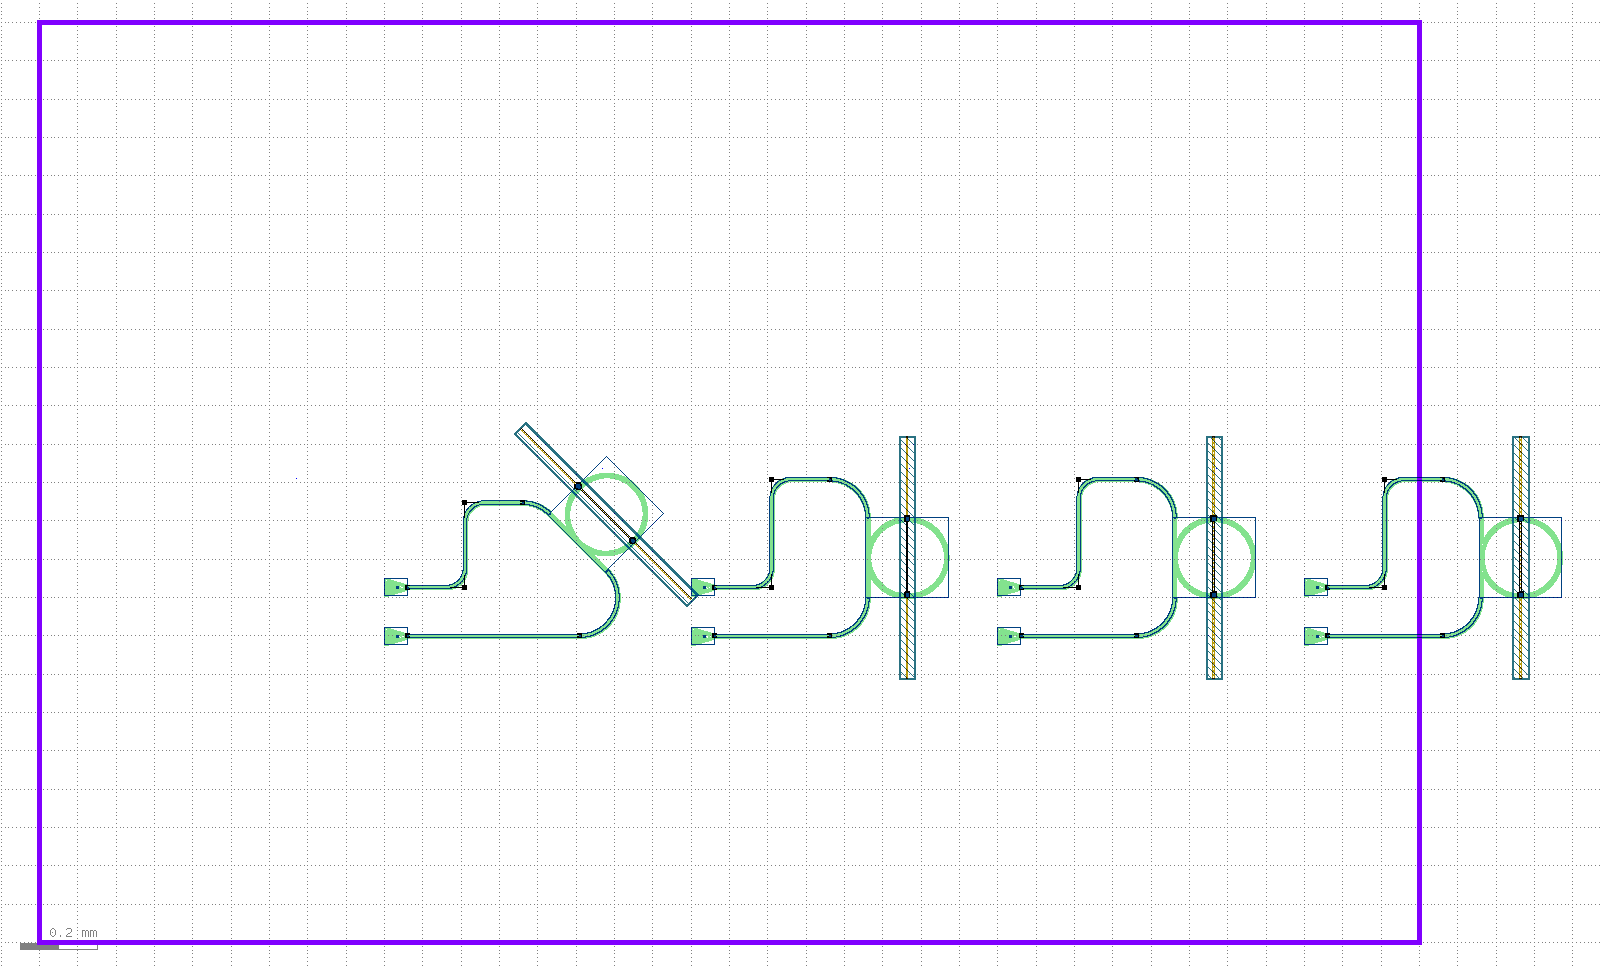

In [ ]:
# change function:
def GC_placement(x,y,GC_pcell,ParentCell,angle=0):

    if angle == 0:
        t = pya.Trans(pya.Trans.R0, x + GC_pcell.bbox().width(), y -  GC_pcell.find_pin("opt1").center.to_dtype(dbu).y)
    else:
        t = pya.DCplxTrans(1.0, angle, False, x + GC_pcell.bbox().width(), y - GC_pcell.bbox().bottom)
    GC_inst = ParentCell.insert(pya.CellInstArray(GC_pcell.cell_index(), t))
    return GC_pcell, GC_inst

def place_VarBEnd(inst4connect,instpin,Bendpin,angle1=-90,angle2=-45):
    VB_pcell = ly.create_cell("BTO_ShEtch_VarBend",tech_name,{
            "wg_width": 1,
            "bend_r": 100,
            "angle1": angle1,
            "angle2": angle2,      
        })
    inst_VarBend = connect_cell(inst4connect, instpin, VB_pcell , Bendpin)
    return VB_pcell, inst_VarBend

def VarBend(x,y,ParentCell,angle1=-90,angle2=-45):
    
    VB_pcell = ly.create_cell("BTO_ShEtch_VarBend",tech_name,{
            "wg_width": 1,
            "bend_r": 100,
            "angle1": angle1,
            "angle2": angle2,      
        })
    t = pya.Trans(pya.Trans.R0, x+0.01e3, y - VB_pcell.bbox().bottom - 9.2e3/2)
    VB_inst = ParentCell.insert(pya.CellInstArray(VB_pcell.cell_index(), t))
    return VB_pcell, VB_inst

def SinglePassRacetrackMod(
    x,
    y,
    ParentCell,
    straight_len_um=100,
    gap_um=0.2,
    radius_um=80,
    wg_width_um=1.0,
    angle_deg=45,
    electrode_width_um=5,
    electrode_gap_um=6,
    electrode_clearance_um=2,
    waveguide_type=None,
    electrode_size_um = 210,
    GC_SETTINGS = None
):
    from SiEPIC.utils.layout import make_pin

    dbu = ly.dbu
    if waveguide_type is None:
        waveguide_type = WG_SETTINGS["wg_type"] if "WG_SETTINGS" in globals() else "Low-loss Bend Waveguide, w=1.2um r=100um"
    wg_half = to_itype(wg_width_um / 2+4, dbu)
    wg_wdith = to_itype(wg_width_um, dbu)
    e_w = to_itype(electrode_width_um, dbu)
    e_gap = to_itype(electrode_gap_um, dbu)
    e_clr = to_itype(electrode_clearance_um, dbu)
    straight = to_itype(straight_len_um, dbu)
    electrode_gap = to_itype(electrode_gap_um, dbu)
    electrode_size = to_itype(electrode_size_um, dbu)

    
    gap_tag = str(gap_um).replace(".", "p")
    base_tag = f"R{int(radius_um)}_G{gap_tag}_L{int(straight_len_um)}_A{int(angle_deg)}"

    # 1) Half-rings
    rt_core = ly.create_cell(f"SP_RacetrackCore_{base_tag}")
    rt_wrapper = ly.create_cell(f"SP_RacetrackWrap_{base_tag}_2")

    gc_distance = 3*127e3
    
    # Add bend
    x_ring = 0
    y_ring = 0
        

    top_half = ly.create_cell(
        "BTO_ShEtch_dc_halfring_straight",
        tech_name,
        {"r": radius_um, "w": wg_width_um, "g": gap_um, "Lc": 0, "AddDrop": True},
    )
    top_inst = rt_core.insert(pya.CellInstArray(top_half.cell_index(), pya.Trans(pya.Trans.R0, 0, 0)))

    bot_half = ly.create_cell(
        "BTO_ShEtch_dc_halfring_straight",
        tech_name,
        {"r": radius_um, "w": wg_width_um, "g": gap_um, "Lc": 0, "AddDrop": False},
    )

    t_bot = pya.Trans(
        pya.Trans.R180,
        0,
        top_inst.bbox().top + to_itype(wg_width_um, dbu) + straight + bot_half.bbox().height() - to_itype(wg_width_um, dbu),
    )
    bot_inst = rt_core.insert(pya.CellInstArray(bot_half.cell_index(), t_bot))

    # 2) Explicit straight waveguides, positioned by waveguide centerlines
    connect_pins_with_waveguide(top_inst,'pin2',bot_inst,'pin4',waveguide_type=wg)
    connect_pins_with_waveguide(top_inst,'pin4',bot_inst,'pin2',waveguide_type=wg)


    ring_x_left = top_inst.bbox().left + wg_half
    ring_x_right = top_inst.bbox().right - wg_half

    # # Vertical centers where straight sections should connect
    y_upper_center = top_inst.bbox().top + wg_half
    y_lower_center = bot_inst.bbox().bottom - wg_half

    y_start = min(y_upper_center, y_lower_center)
    y_end = max(y_upper_center, y_lower_center)
    straight_len_actual_um = (y_end - y_start) * dbu

    for cx in (ring_x_left, ring_x_right):
        wg_straight = ly.create_cell(
            "Waveguide",
            tech_name,
            {
                "path": pya.DPath([pya.DPoint(0, 0), pya.DPoint(0, straight_len_actual_um)], wg_width_um),
                "waveguide_type": waveguide_type,
            },
        )
        rt_core.insert(
            pya.CellInstArray(
                wg_straight.cell_index(),
                pya.Trans(pya.Trans.R0, cx - wg_half, y_start),
            )
        )

    # 3) Electrodes (3 strips)
    ring_x_left = top_inst.bbox().left + wg_half
    ring_x_right = top_inst.bbox().right - wg_half

    y_upper_center = bot_inst.bbox().bottom + 0.1
    y_lower_center = top_inst.bbox().top - 0.1

    y_start = min(y_upper_center, y_lower_center)
    y_end = max(y_upper_center, y_lower_center)
    straight_len_actual_um = (y_end - y_start) * dbu

    metal_layer = ly.layer(ly.TECHNOLOGY["Gold"])
    clad_layer = ly.layer(ly.TECHNOLOGY["fast_exposure"]) if "BTO_clad" in ly.TECHNOLOGY else None

    # print(f"wg_half: {wg_half}, y_upper_center: {y_upper_center}, y_lower_center: {y_lower_center}, straight_len_actual_um: {straight_len_actual_um}")
    xl_e = ring_x_left - wg_half
    xr_e = ring_x_right + wg_half

    y_upper = y_upper_center
    y_lower = y_lower_center

    # Electrode 1: at the middle, centered between the two waveguides
    rt_core.shapes(metal_layer).insert(
        pya.Box(xl_e + wg_half + wg_wdith/2+electrode_gap/2, y_upper, xr_e - wg_half-electrode_gap/2, y_lower)
    )
    # Electrodes 2 and 3: above and below the waveguides, separated by e_gap from the center electrode and wg edge
    rt_core.shapes(metal_layer).insert(
        pya.Box(xl_e + wg_half-wg_wdith/2-electrode_gap/2, y_upper, xl_e-electrode_size, y_lower)
    )
    rt_core.shapes(metal_layer).insert(
        pya.Box(xr_e - wg_half+wg_wdith/2+electrode_gap/2, y_upper, xr_e+electrode_size, y_lower)
    )

    y_cen_top = y_upper - wg_half - e_gap
    y_cen_bot = y_lower + wg_half + e_gap
    
    # if y_cen_top > y_cen_bot:
    #     rt_core.shapes(metal_layer).insert(pya.Box(xl_e, y_cen_bot, xr_e, y_cen_top))

    if clad_layer is not None:
        rt_core.shapes(clad_layer).insert(
            pya.Box(
                # xl_e - e_clr,
                xl_e-electrode_size  - e_clr,
                y_lower - wg_half - e_gap - e_w - e_clr,
                # xr_e + e_clr,
                xr_e+electrode_size + e_clr,
                y_upper + wg_half + e_gap + e_w + e_clr,
            )
        )

    angle1 = (0)
    angle2 = angle_deg

    [VB_pcell1,VB_inst1] = place_VarBEnd(inst4connect = top_inst, instpin='pin1', Bendpin='pin1', angle1=angle1+90, angle2=angle2+90)
    if angle_deg < 46:
        [VB_pcell2,VB_inst2] = place_VarBEnd(inst4connect = top_inst, instpin='pin3', Bendpin='pin1', angle1=angle1, angle2=angle2-180)

    else:
        [VB_pcell2,VB_inst2] = place_VarBEnd(inst4connect = top_inst, instpin='pin3', Bendpin='pin1', angle1=angle1, angle2=angle2-180)

    # 4) Wrapper rotation: clockwise for positive angle_deg
    rot = pya.DCplxTrans(1.0, -angle_deg, False, 0, 0)
    core_inst = rt_wrapper.insert(pya.CellInstArray(rt_core.cell_index(), rot))

    # Avoid ambiguous global pin lookup in rt_core; use the known top half pins and transform.
    pinup_local = VB_inst1.find_pin("pin2").center.to_dtype(dbu)
    pindw_local = VB_inst2.find_pin("pin2").center.to_dtype(dbu)
    pin1_pt = rot * pinup_local 
    pin3_pt = rot * pindw_local

    make_pin(rt_wrapper, "pin_in", pin1_pt, 0.02*dbu, ly.TECHNOLOGY["PinRec"], 180)
    make_pin(rt_wrapper, "pin_out", pin3_pt, 0.02*dbu, ly.TECHNOLOGY["PinRec"], 180)

    # 5) Place wrapper and GCs inside a container cell
    # Choose vertical anchor: "pin_out" or "bottom"
    y_anchor_mode = "pin_bottom"
    if y_anchor_mode == "bottom":
        y_anchor_local = rt_wrapper.bbox().bottom
    elif y_anchor_mode == "pin_up":
        y_anchor_local = to_itype(rt_wrapper.find_pin("pin_in").center.to_dtype(dbu).y, dbu)
    elif y_anchor_mode == "pin_bottom":
        y_anchor_local = to_itype(rt_wrapper.find_pin("pin_out").center.to_dtype(dbu).y, dbu)
    y_shift = -y_anchor_local

    # Create a container cell that holds both the ring wrapper and the GCs
    rt_with_gc = ly.create_cell(f"SP_RT_GC_{base_tag}")
    rt_wrapper_inst = rt_with_gc.insert(pya.CellInstArray(rt_wrapper.cell_index(), pya.Trans(pya.Trans.R0, 0, y_shift)))

    # Keep GC opt1 x-position fixed 300 um to the left of pin_in.
    pin_in_x = to_itype(rt_wrapper_inst.find_pin("pin_in").center.to_dtype(dbu).x, dbu)
    pin_in_gc_dx = to_itype(300, dbu)

    if GC_SETTINGS["gc_cell_name"] == "BTO_Universal_GC":
        gc_probe = ly.create_cell(GC_SETTINGS["gc_cell_name"], GC_SETTINGS["gc_library"], GC_SETTINGS.get("parameters", {}))
    else:
        gc_probe = ly.create_cell(GC_SETTINGS["gc_cell_name"], GC_SETTINGS["gc_library"])
    gc_pin_local_x = to_itype(gc_probe.find_pin("opt1").center.to_dtype(dbu).x, dbu)
    target_gc_opt1_x = pin_in_x - pin_in_gc_dx
    gc_x = target_gc_opt1_x - gc_probe.bbox().width() - gc_pin_local_x

    # Vertical spacing between the two GCs fixed at 127 um
    pin3_y = to_itype(rt_wrapper_inst.find_pin("pin_out").center.to_dtype(dbu).y, dbu)
    print(f"pin3_y applied to wrapper: {pin3_y*dbu} um")

    gc_pitch = to_itype(127 * 1, dbu)
    
    try:
        gc2_y = pin3_y - gc_probe.find_pin("opt1").center.to_dtype(dbu).y
    except Exception:
        # gc_pin_probe_y = 0.0
        gc2_y = pin3_y
    print(f"gc2_y applied to wrapper: {gc2_y*dbu} um")

    gc1_y = gc2_y + gc_pitch

    _, gc1_inst = GC_placement(gc_x, gc1_y, GC_pcell=gc_probe, ParentCell=rt_with_gc, angle=0)
    _, gc2_inst = GC_placement(gc_x, gc2_y, GC_pcell=gc_probe, ParentCell=rt_with_gc, angle=0)

    connect_pins_with_waveguide(rt_wrapper_inst, "pin_in", gc1_inst, "opt1", waveguide_type=waveguide_type)
    connect_pins_with_waveguide(rt_wrapper_inst, "pin_out", gc2_inst, "opt1", waveguide_type=waveguide_type)

    # Place using a loopback-style anchor: bottom GC opt1 at (gc_bbox.width, 0)
    gc2_pin_x = to_itype(gc2_inst.find_pin("opt1").center.to_dtype(dbu).x, dbu)
    gc2_pin_y = to_itype(gc2_inst.find_pin("opt1").center.to_dtype(dbu).y, dbu)
    gc_anchor_x = gc_probe.bbox().width()
    gc_anchor_y = 0
    place_x = x + (gc_anchor_x - gc2_pin_x)
    place_y = y + (gc_anchor_y - gc2_pin_y)
    rt_inst = ParentCell.insert(pya.CellInstArray(rt_with_gc.cell_index(), pya.Trans(pya.Trans.R0, place_x, place_y)))
    return rt_with_gc, rt_inst, gc1_inst, gc2_inst


# ===== Example =====
cellname = "SP_RacetrackMod_Block"
topcell, ly = new_layout(tech_name, cellname, GUI=True, overwrite=True)

FP = pya.Box(0, 0, 3600e3, 2400e3)
topcell.shapes(ly.layer(ly.TECHNOLOGY["FloorPlan"])).insert(FP)

wg = WG_SETTINGS["wg_type"] if "WG_SETTINGS" in globals() else "Low-loss Bend Waveguide, w=1.2um r=100um"

# (radius_um, gap_um, straight_len_um, angle_deg)
params = [
    (100, 0.20, 0, 45),
    (100, 0.25, 0, 90),
    (100, 0.30, 0, 90),
    (100, 0.35, 0, 90),
]

x0 = 900e3
y0 = 800e3
dx = 800e3

x = x0
for i, (rad_um, gap_um, Lc_um, ang) in enumerate(params):
    _, rt_inst, _, _ = SinglePassRacetrackMod(
        x=x,
        y=y0,
        ParentCell=topcell,
        straight_len_um=Lc_um,
        gap_um=gap_um,
        radius_um=rad_um,
        angle_deg=ang,
        electrode_gap_um=6.2,
        waveguide_type=wg,
        GC_SETTINGS=GC_SETTINGS_UNIVERSAL,
    )
    label = pya.Text(
        f"opt_in_TE_1550_device_SPRT{i}_R{rad_um}_G{gap_um}_L{Lc_um}_A{ang}",
        pya.Trans(pya.Trans.R0, x - 230e3, y0 + rt_inst.bbox().height() // 2 + 120e3),
    )
    topcell.shapes(ly.layer(ly.TECHNOLOGY["Text"])).insert(label)
    x += dx

topcell.show()
topcell.plot()
